# Problema 5 – Segmentação de Clientes Utilizando k-Means

PAM0466 – Sistemas Inteligentes

Um distribuidor atacadista atende, ao mesmo tempo, clientes muito diferentes entre si: o restaurante que compra hortifrúti e congelados em alto giro, o pequeno mercado de bairro que se abastece de mercearia, laticínios e produtos de limpeza, entre outros. Tratar todos eles com a mesma política comercial é, na prática, desperdiçar margem e capacidade logística.

A segmentação de clientes tem aplicações diretas no planejamento de rotas e estoques, na definição de campanhas promocionais dirigidas, na concessão de limites de crédito e na identificação de clientes atípicos, que merecem atendimento dedicado. No Brasil, o crescimento do modelo de atacarejo e a importância dos distribuidores regionais no abastecimento do interior do Nordest, tornam o problema especialmente concreto para a nossa realidade.

Este projeto tem uma característica que o distingue dos anteriores: não existe um rótulo a ser previsto. Ninguém classificou previamente os clientes em “perfil restaurante” ou “perfil varejo’, se esses grupos existem, eles precisam emergir da própria estrutura dos gastos. É o domínio do aprendizado não supervisionado.

Neste projeto, você é convidado a identificar perfis de consumo de clientes de um distribuidor atacadista por meio do algoritmo de agrupamento k-Means.

O projeto utiliza o arquivo Wholesale customers data.csv do dataset Wholesale Customers (https://archive.ics.uci.edu/dataset/292/wholesale+customers). O dataset foi doado por Margarida G. M. S. Cardoso (ISCTE-IUL, Lisboa, Portugal) em 2014 e reúne 440 clientes de um distribuidor atacadista português. Para cada cliente são registrados os gastos anuais, em unidades monetárias, em seis categorias de produto — Fresh (frescos), Milk (laticínios), Grocery (mercearia), Frozen (congelados), Detergents Paper (detergentes e papel) e Delicassen (delicatessen) — além de dois atributos categóricos: Channel, indicando se o cliente pertence ao canal Horeca (hotéis, restaurantes e cafés, 298 clientes) ou Retail (varejo, 142 clientes), e Region, indicando sua localização (Lisboa, Porto ou outras regiões).

Observação: os atributos Channel e Region não devem ser utilizados no agrupamento. Eles serão reservados para a validação externa da tarefa 5. O agrupamento deve basear-se exclusivamente nas seis categorias de gasto.

Realize as seguintes tarefas utilizando o dataset fornecido:

1. Preparação dos dados: carregue o dataset e separe Channel e Region do restante. Para cada uma das seis categorias de gasto, calcule média, mediana, desvio padrão e valores extremos, e construa um boxplot ou histograma. Você observará distribuições fortemente assimétricas à direita, com poucos clientes de gasto muito elevado — em Fresh, por exemplo, os valores vão de dezenas a mais de cem mil unidades monetárias. Aplique então a transformação logarítmica x' = log(1 + x) e, em seguida, padronize os atributos por Z-score. Justifique as duas etapas separadamente: (a) por que a transformação logarítmica é recomendável diante da assimetria e da presença de outliers, e (b) por que a padronização é determinante para o k-Means, relacionando sua resposta ao uso da distância euclidiana na atribuição dos pontos aos centróides. Calcule também a matriz de correlação entre as seis categorias e comente o par Grocery–Detergents Paper.
2. Ausência de divisão treino/teste: diferentemente dos projetos anteriores, aqui não se separa um conjunto de teste. Explique por quê, contrastando o objetivo do aprendizado supervisionado (estimar o erro de generalização sobre rótulos conhecidos) com o do não supervisionado. Discuta, então, qual é a dificuldade central da validação em agrupamento: como afirmar que uma partição é “boa” sem dispor de um gabarito?
3. Escolha do número de grupos: execute o k-Means para k variando de 2 a 10. Plote a inércia (soma dos quadrados intra-cluster) em função de k e aplique o método do cotovelo; em seguida, plote o coeficiente de silhueta médio em função de k. Escolha o valor de k justificando sua decisão à luz dos dois critérios e da interpretabilidade comercial dos grupos resultantes — um segmento só é útil se a área comercial souber o que fazer com ele. Responda: por que a inércia decresce monotonicamente com k e por que, portanto, ela não pode ser usada isoladamente como critério de escolha? O que ocorre no caso limite em que k é igual ao número de amostras?
4. Inicialização e convergência: o k-Means converge para um mínimo local, e não necessariamente global. Execute o algoritmo dez vezes com init='random' e n_init=1, usando sementes distintas, e registre a inércia final de cada execução. Repita o procedimento com init='k-means++'. Compare a dispersão dos resultados nos dois casos e explique qual problema a inicialização k-means++ busca mitigar e de que forma.
5. Interpretação e validação dos grupos: com o k escolhido, recupere os centróides, reverta-os para a escala original de gasto (desfazendo a padronização e a transformação logarítmica) e apresente-os em uma tabela e em um gráfico de barras agrupadas por categoria. Atribua a cada agrupamento um nome descritivo de natureza comercial, baseado nas categorias em que ele se destaca. Em seguida, realize uma validação externa: construa tabelas de contingência cruzando o agrupamento de cada cliente com Channel e com Region, e calcule o índice Rand ajustado (Adjusted Rand Index) entre a partição obtida e a variável Channel. Responda: o algoritmo, sem jamais ter visto o canal de venda, foi capaz de reconstruí-lo? Qual conjunto de categorias de produto mais separa Horeca de Retail? E a região geográfica — ela se reflete nos agrupamentos? Por fim, projete os dados em duas dimensões por PCA, colorindo os pontos por agrupamento, e discuta duas limitações do k-Means evidenciadas nesse gráfico: a tendência a formar grupos de geometria esférica e de tamanhos semelhantes e a sensibilidade a outliers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42   # semente usada em todo o notebook (reprodutibilidade)

In [2]:
# carrega o arquivo Wholesale customers data.csv (colunas separadas por vírgula)
df = pd.read_csv('Wholesale_customers_data_questao5.csv')
print('Formato (clientes, colunas):', df.shape)
df.head()

Formato (clientes, colunas): (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## Tarefa 1 - Preparação dos dados: carregue o dataset e separe Channel e Region do restante. Para cada uma das seis categorias de gasto, calcule média, mediana, desvio padrão e valores extremos, e construa um boxplot ou histograma. Você observará distribuições fortemente assimétricas à direita, com poucos clientes de gasto muito elevado — em Fresh, por exemplo, os valores vão de dezenas a mais de cem mil unidades monetárias. Aplique então a transformação logarítmica x' = log(1 + x) e, em seguida, padronize os atributos por Z-score. Justifique as duas etapas separadamente: (a) por que a transformação logarítmica é recomendável diante da assimetria e da presença de outliers, e (b) por que a padronização é determinante para o k-Means, relacionando sua resposta ao uso da distância euclidiana na atribuição dos pontos aos centróides. Calcule também a matriz de correlação entre as seis categorias e comente o par Grocery–Detergents Paper.

In [3]:
gastos = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]

# Channel e Region são separados do restante: ficam reservados só para a validação externa (Tarefa 5)
externos = df[["Channel", "Region"]].copy()
externos["Channel_nome"] = externos["Channel"].map({1: "Horeca", 2: "Retail"})
externos["Region_nome"] = externos["Region"].map({1: "Lisboa", 2: "Porto", 3: "Outras"})

# única entrada do agrupamento: as seis categorias de gasto
X = df[gastos].copy()

print('Valores ausentes:', int(df.isnull().sum().sum()))
print('Channel:', externos["Channel_nome"].value_counts().to_dict())
print('Region :', externos["Region_nome"].value_counts().to_dict())

Valores ausentes: 0
Channel: {'Horeca': 298, 'Retail': 142}
Region : {'Outras': 316, 'Lisboa': 77, 'Porto': 47}


In [4]:
# estatísticas descritivas de cada categoria: média, mediana, desvio padrão, mínimo e máximo
# (assimetria > 0 = cauda longa à direita: poucos clientes gastam muito mais que o típico)
desc = X.agg(["mean", "median", "std", "min", "max"]).T
desc["assimetria"] = X.skew()
print(desc.round(2).to_string())

                      mean  median       std   min       max  assimetria
Fresh             12000.30  8504.0  12647.33   3.0  112151.0        2.56
Milk               5796.27  3627.0   7380.38  55.0   73498.0        4.05
Grocery            7951.28  4755.5   9503.16   3.0   92780.0        3.59
Frozen             3071.93  1526.0   4854.67  25.0   60869.0        5.91
Detergents_Paper   2881.49   816.5   4767.85   3.0   40827.0        3.63
Delicassen         1524.87   965.5   2820.11   3.0   47943.0       11.15


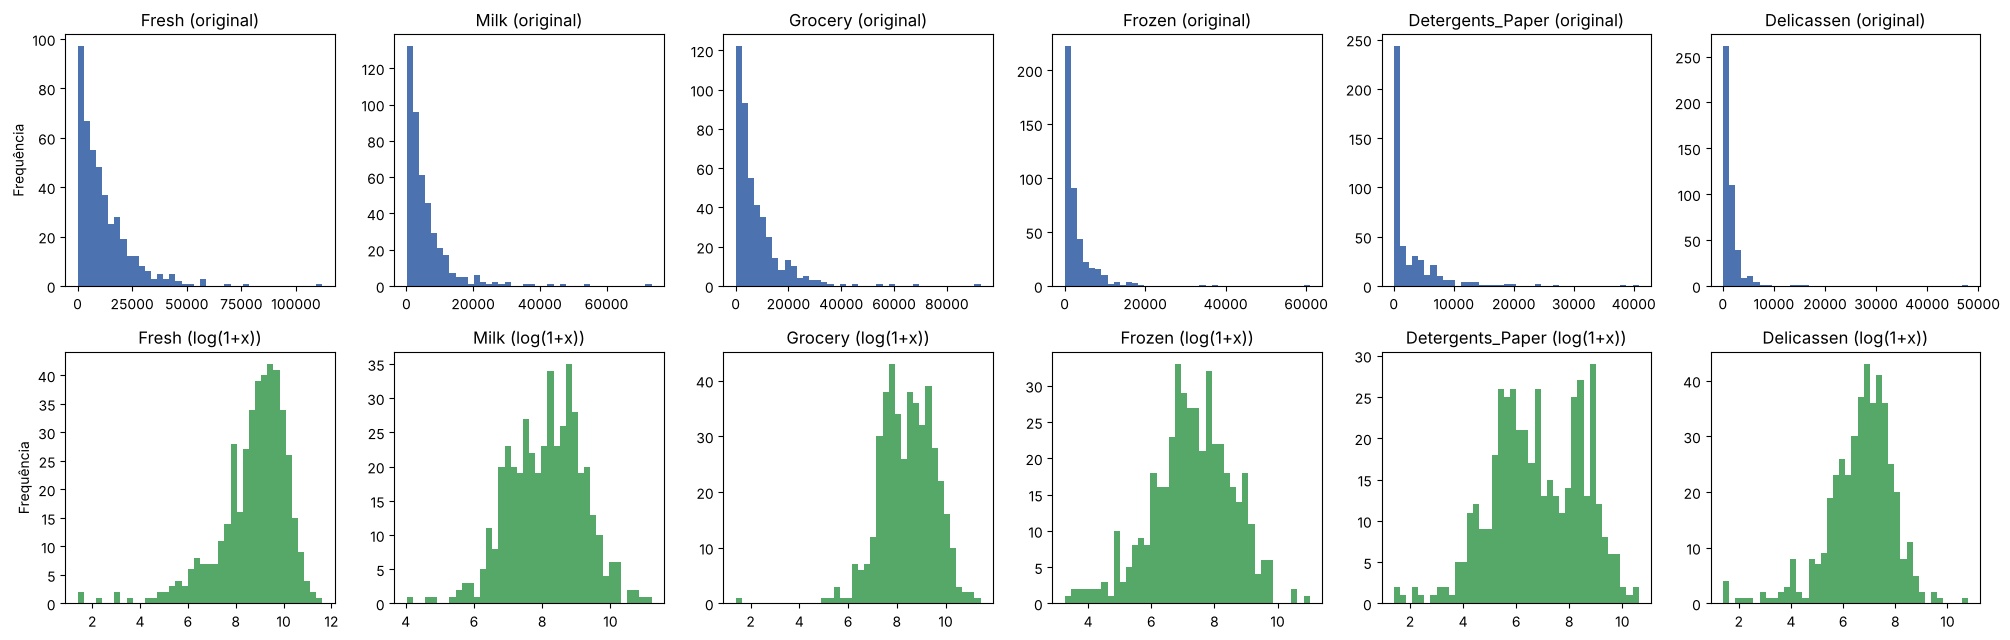

In [5]:
# histogramas: escala original (linha de cima) e após log(1+x) (linha de baixo)
fig, eixos = plt.subplots(2, 6, figsize=(20, 6.5))
for j, c in enumerate(gastos):
    eixos[0, j].hist(X[c], bins=40, color="#4C72B0"); eixos[0, j].set_title(f"{c} (original)")
    eixos[1, j].hist(np.log1p(X[c]), bins=40, color="#55A868"); eixos[1, j].set_title(f"{c} (log(1+x))")
eixos[0, 0].set_ylabel("Frequência"); eixos[1, 0].set_ylabel("Frequência")
plt.tight_layout()
plt.show()

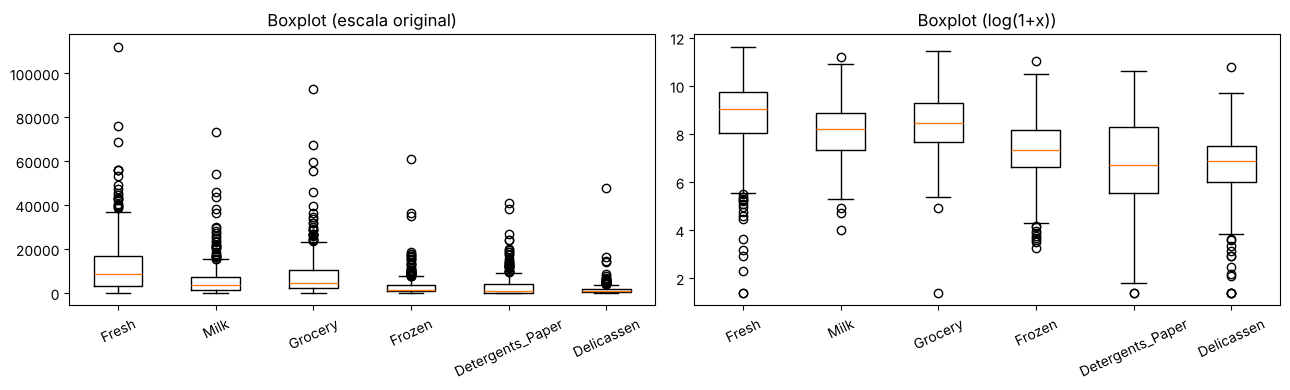

In [6]:
# boxplots: escala original e após log(1+x) (os pontos fora das "caixas" são os outliers)
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
eixos[0].boxplot([X[c] for c in gastos]); eixos[0].set_title("Boxplot (escala original)")
eixos[1].boxplot([np.log1p(X[c]) for c in gastos]); eixos[1].set_title("Boxplot (log(1+x))")
for e in eixos:
    e.set_xticks(range(1, 7)); e.set_xticklabels(gastos, rotation=25)
plt.tight_layout()
plt.show()

### Transformação logarítmica e padronização

$$ x' = \log(1 + x) \qquad\qquad z = \frac{x' - \mu}{\sigma} $$

A ordem importa: **primeiro o log, depois o Z-score**. O `+1` evita o logaritmo de zero.

In [7]:
# 1º passo: transformação logarítmica log(1 + x) (np.log1p); 2º passo: Z-score (StandardScaler)
X_log = np.log1p(X)
scaler = StandardScaler().fit(X_log)
Z = scaler.transform(X_log)       # matriz padronizada: entrada do k-Means

print("Assimetria antes do log :", X.skew().round(2).to_dict())
print("Assimetria depois do log:", X_log.skew().round(2).to_dict())
print()
print("Média de Z  (esperado ≈ 0):", Z.mean(axis=0).round(6))
print("Desvio de Z (esperado = 1):", Z.std(axis=0).round(6))

Assimetria antes do log : {'Fresh': 2.56, 'Milk': 4.05, 'Grocery': 3.59, 'Frozen': 5.91, 'Detergents_Paper': 3.63, 'Delicassen': 11.15}
Assimetria depois do log: {'Fresh': -1.58, 'Milk': -0.22, 'Grocery': -0.67, 'Frozen': -0.35, 'Detergents_Paper': -0.24, 'Delicassen': -1.09}

Média de Z  (esperado ≈ 0): [ 0. -0. -0.  0. -0. -0.]
Desvio de Z (esperado = 1): [1. 1. 1. 1. 1. 1.]


In [8]:
# evidência prática de (a): k-Means com k = 3 SEM o log (só Z-score) e COM log + Z-score
Z_sem_log = StandardScaler().fit_transform(X)
km_sem_log = KMeans(3, n_init=10, random_state=SEED).fit(Z_sem_log)
km_com_log = KMeans(3, n_init=10, random_state=SEED).fit(Z)

print("Tamanhos dos grupos SEM log:", sorted(np.bincount(km_sem_log.labels_).tolist()))
print("Tamanhos dos grupos COM log:", sorted(np.bincount(km_com_log.labels_).tolist()))

Tamanhos dos grupos SEM log: [2, 45, 393]
Tamanhos dos grupos COM log: [80, 147, 213]


In [9]:
# evidência prática de (b): variância de cada categoria na escala original (o que domina a distância euclidiana)
print("Variância SEM padronizar:")
print(X.var().round(0).to_string())

Variância SEM padronizar:
Fresh               159954927.0
Milk                 54469967.0
Grocery              90310104.0
Frozen               23567853.0
Detergents_Paper     22732436.0
Delicassen            7952997.0


In [10]:
# matriz de correlação (Pearson) entre as seis categorias, na escala original e em log
corr_original = X.corr()
corr_log = X_log.corr()
print("Correlação (escala original):")
print(corr_original.round(2).to_string())
print()
print("Correlação (log):")
print(corr_log.round(2).to_string())
print()
print(f"Par Grocery–Detergents_Paper: original = {corr_original.loc['Grocery', 'Detergents_Paper']:.2f} | log = {corr_log.loc['Grocery', 'Detergents_Paper']:.2f}")

Correlação (escala original):
                  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
Fresh              1.00  0.10    -0.01    0.35             -0.10        0.24
Milk               0.10  1.00     0.73    0.12              0.66        0.41
Grocery           -0.01  0.73     1.00   -0.04              0.92        0.21
Frozen             0.35  0.12    -0.04    1.00             -0.13        0.39
Detergents_Paper  -0.10  0.66     0.92   -0.13              1.00        0.07
Delicassen         0.24  0.41     0.21    0.39              0.07        1.00

Correlação (log):
                  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
Fresh              1.00 -0.02    -0.13    0.39             -0.16        0.26
Milk              -0.02  1.00     0.76   -0.06              0.68        0.34
Grocery           -0.13  0.76     1.00   -0.16              0.80        0.24
Frozen             0.39 -0.06    -0.16    1.00             -0.21        0.26
Detergents_Paper  -0.16  0.

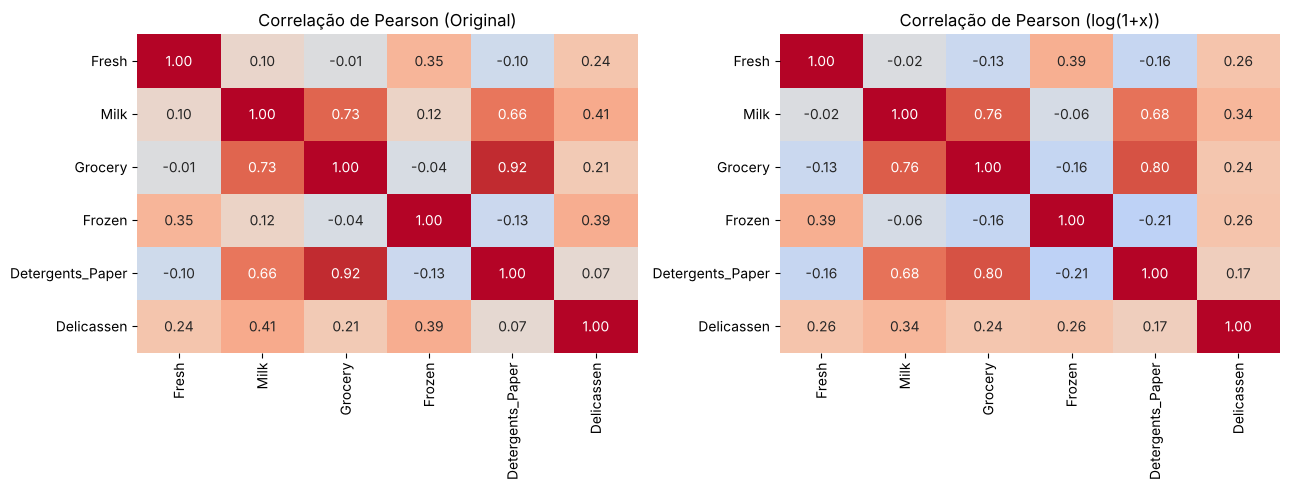

In [11]:
# mapas de calor das duas matrizes
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
for eixo, cm, t in zip(eixos, [corr_original, corr_log], ["Original", "log(1+x)"]):
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=eixo, cbar=False)
    eixo.set_title(f"Correlação de Pearson ({t})")
plt.tight_layout()
plt.show()

**Resposta.**

Todas as categorias têm média maior que a mediana e assimetria positiva alta (tabela de estatísticas acima): poucos clientes gastam muito mais que o típico (histogramas e boxplots). Em Fresh, por exemplo, o máximo passa de 100 mil contra uma mediana na casa de 8,5 mil. Após o `log(1+x)` as assimetrias caem bastante.

**(a) Por que o log.** O k-Means minimiza uma soma de **quadrados** e o centróide é uma **média**. Um cliente 10 vezes maior pesa 100 vezes mais no erro quadrático e puxa o centróide, e os grupos acabam sendo definidos pelos outliers. O log comprime a cauda (passa a contar a ordem de grandeza do gasto) e deixa a distribuição mais simétrica. O experimento acima mostra o efeito: sem o log, com k = 3, o k-Means gera grupos de tamanho muito desiguais (dois deles minúsculos, apenas para isolar outliers); com o log, os grupos têm tamanhos razoáveis.

**(b) Por que o Z-score.** Cada ponto é atribuído ao centróide de menor distância euclidiana, $\lVert x-\mu\rVert^2 = \sum_j (x_j-\mu_j)^2$. Uma variável de escala grande domina essa soma e as outras quase não influenciam a atribuição (a variância de Fresh, impressa acima, é muito maior que a de Delicassen). O Z-score deixa todas com média 0 e desvio 1, para que contem igual. O log corrige a **forma** (assimetria) e o Z-score corrige a **escala**, por isso as duas etapas são justificadas separadamente.

**Correlações e o par Grocery–Detergents_Paper.** Esse é o par mais fortemente correlacionado de todos (r ≈ 0,92 na escala original e ≈ 0,80 em log): quem compra muita mercearia compra muito detergente e papel, o que reflete o perfil de varejo, que compra esses itens juntos. Milk também se correlaciona com os dois. Para o k-Means isso é informação **redundante**: o eixo "mercearia/limpeza" acaba com peso dobrado no cálculo da distância.

## Tarefa 2 - Ausência de divisão treino/teste: diferentemente dos projetos anteriores, aqui não se separa um conjunto de teste. Explique por quê, contrastando o objetivo do aprendizado supervisionado (estimar o erro de generalização sobre rótulos conhecidos) com o do não supervisionado. Discuta, então, qual é a dificuldade central da validação em agrupamento: como afirmar que uma partição é “boa” sem dispor de um gabarito?

**Resposta.** No aprendizado **supervisionado** existe um rótulo e o objetivo é **generalizar**: estimar o erro em dados novos comparando a previsão com o rótulo conhecido. Por isso se guarda um conjunto de teste, que o modelo nunca viu. No **não supervisionado** não há rótulo, logo não existe "erro de generalização" a estimar; o objetivo é **descobrir estrutura** nos dados disponíveis. Aqui, os 440 clientes são toda a população do distribuidor que se quer segmentar, e o resultado é usado nesses mesmos clientes, então não faz sentido reservar uma parte deles.

**Dificuldade central da validação:** sem gabarito, "partição boa" não tem uma definição única.
- Os **índices internos** (inércia, silhueta) medem coesão e separação, mas favorecem grupos esféricos e podem discordar entre si.
- Os **índices externos** (como o ARI) precisam de rótulos, que normalmente não existem.
- Há ainda o critério prático: a área comercial precisa saber o que fazer com cada segmento.

Por isso a validação combina várias evidências, como é feito nas tarefas seguintes.

## Tarefa 3 - Escolha do número de grupos: execute o k-Means para k variando de 2 a 10. Plote a inércia (soma dos quadrados intra-cluster) em função de k e aplique o método do cotovelo; em seguida, plote o coeficiente de silhueta médio em função de k. Escolha o valor de k justificando sua decisão à luz dos dois critérios e da interpretabilidade comercial dos grupos resultantes — um segmento só é útil se a área comercial souber o que fazer com ele. Responda: por que a inércia decresce monotonicamente com k e por que, portanto, ela não pode ser usada isoladamente como critério de escolha? O que ocorre no caso limite em que k é igual ao número de amostras?

$$ Inércia = \sum_{j=1}^{k} \sum_{x_i \in C_j} \lVert x_i - \mu_j \rVert^2 \qquad\qquad s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}} $$

- Inércia: soma dos quadrados das distâncias de cada ponto ao centróide do seu grupo (quanto menor, grupos mais compactos).
- Silhueta: $a(i)$ é a distância média do ponto $i$ aos outros do **seu** grupo; $b(i)$ é a distância média ao grupo **vizinho** mais próximo. Perto de 1 = bem alocado; perto de 0 = na fronteira; negativa = provavelmente no grupo errado.
- Leitura da silhueta média: acima de 0,70 estrutura forte; de 0,51 a 0,70 razoável; de 0,26 a 0,50 fraca; até 0,25 sem estrutura.

In [12]:
# executa o k-Means para k = 2, ..., 10 e guarda inércia e silhueta média de cada k
ks = list(range(2, 11))
linhas = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    linhas.append({"k": k, "inercia": km.inertia_, "silhueta": silhouette_score(Z, km.labels_)})

met = pd.DataFrame(linhas).set_index("k")
# queda percentual da inércia em relação ao k anterior (ajuda a identificar o "cotovelo")
met["queda_inercia_%"] = 100 * (met["inercia"].shift(1) - met["inercia"]) / met["inercia"].shift(1)
print(met.round(3).to_string())

     inercia  silhueta  queda_inercia_%
k                                      
2   1844.064     0.290              NaN
3   1553.421     0.259           15.761
4   1386.863     0.188           10.722
5   1266.149     0.192            8.704
6   1174.759     0.201            7.218
7   1086.359     0.196            7.525
8   1028.486     0.185            5.327
9    973.141     0.197            5.381
10   931.998     0.191            4.228


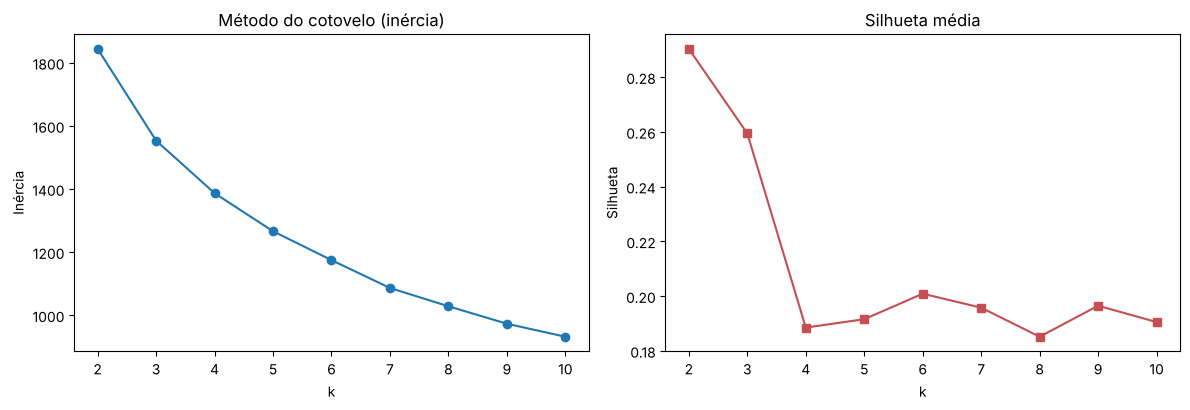

In [13]:
# método do cotovelo (inércia x k) e silhueta média x k
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.2))
eixos[0].plot(ks, met["inercia"], "o-"); eixos[0].set_title("Método do cotovelo (inércia)")
eixos[0].set_xlabel("k"); eixos[0].set_ylabel("Inércia")
eixos[1].plot(ks, met["silhueta"], "s-", color="#C44E52"); eixos[1].set_title("Silhueta média")
eixos[1].set_xlabel("k"); eixos[1].set_ylabel("Silhueta")
for e in eixos:
    e.set_xticks(ks)
plt.tight_layout()
plt.show()

In [14]:
# caso limite: k = n (cada cliente é o seu próprio centróide)
km_n = KMeans(n_clusters=len(Z), n_init=1, random_state=SEED).fit(Z)
print(f"k = n = {len(Z)}: inércia = {km_n.inertia_:.6f}")

# k = 1: um único grupo; a inércia é a variação total dos dados (SST)
print(f"k = 1: inércia = SST = {((Z - Z.mean(0))**2).sum():.1f}")

# a silhueta não é definida quando cada grupo tem um único ponto
try:
    silhouette_score(Z, km_n.labels_)
except Exception as e:
    print("Silhueta com k = n não é definida:", type(e).__name__)

k = n = 440: inércia = 0.000000
k = 1: inércia = SST = 2640.0
Silhueta com k = n não é definida: ValueError


In [15]:
K = 3   # k escolhido (justificativa na resposta abaixo)

# modelo final com k = 3
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Z)
rotulo_bruto = km.labels_

# qualidade de cada grupo: tamanho, silhueta média e % de pontos com silhueta negativa (mal alocados)
s_i = silhouette_samples(Z, rotulo_bruto)
for c in range(K):
    m = rotulo_bruto == c
    print(f"grupo {c}: n = {m.sum():3d} | silhueta média = {s_i[m].mean():.3f} | % com silhueta < 0: {(s_i[m] < 0).mean():.1%}")

grupo 0: n =  80 | silhueta média = 0.121 | % com silhueta < 0: 25.0%
grupo 1: n = 147 | silhueta média = 0.282 | % com silhueta < 0: 0.0%
grupo 2: n = 213 | silhueta média = 0.296 | % com silhueta < 0: 1.4%


**Resposta. Escolha: k = 3.**
- **Cotovelo:** a curva da inércia é suave, sem joelho nítido; a maior queda marginal ocorre de k = 2 para k = 3 (coluna `queda_inercia_%`), e depois as quedas ficam menores e parecidas.
- **Silhueta:** é máxima em k = 2, mas k = 3 mantém um valor próximo e **cai para ≈ 0,19 a partir de k = 4**. Todos os valores ficam na faixa de estrutura **fraca** (0,26 a 0,50) ou abaixo, ou seja, os dados formam uma nuvem contínua e não grupos bem separados.
- **Interpretabilidade comercial:** k = 2 só reproduz a divisão Horeca × Retail, que já é conhecida; k = 3 entrega um terceiro segmento acionável (os grandes compradores); k ≥ 4 cria grupos pequenos e difíceis de distinguir comercialmente.

**Por que a inércia decresce monotonicamente com k?** Dividir um grupo em dois nunca aumenta a soma dos quadrados (dois centróides representam um conjunto ao menos tão bem quanto um), então a inércia ótima com k + 1 grupos é menor ou igual à de k. Se a minimizássemos, escolheríamos sempre o maior k possível, por isso ela não serve sozinha como critério.

**Caso k = n:** cada cliente vira o seu próprio centróide e a inércia vale **0** (verificado na saída acima). É uma partição perfeita e inútil (não resume nada), e a silhueta nem é definida. Para k = 1 a inércia é a variação total dos dados.

## Tarefa 4 - Inicialização e convergência: o k-Means converge para um mínimo local, e não necessariamente global. Execute o algoritmo dez vezes com init='random' e n_init=1, usando sementes distintas, e registre a inércia final de cada execução. Repita o procedimento com init='k-means++'. Compare a dispersão dos resultados nos dois casos e explique qual problema a inicialização k-means++ busca mitigar e de que forma.

In [16]:
def roda(init, k, sementes):
    # executa o k-Means uma vez por semente (n_init=1 = uma única inicialização) e devolve a inércia final de cada execução
    return np.array([KMeans(n_clusters=k, init=init, n_init=1, random_state=s).fit(Z).inertia_ for s in sementes])

sementes = range(10)                      # dez sementes distintas
J_random = roda("random", K, sementes)    # centróides iniciais sorteados ao acaso
J_pp = roda("k-means++", K, sementes)     # centróides iniciais espalhados (k-means++)

# inércia final de cada execução
tabela = pd.DataFrame({"semente": list(sementes), "random": J_random.round(2), "k-means++": J_pp.round(2)}).set_index("semente")
print(tabela.to_string())

          random  k-means++
semente                    
0        1553.39    1553.77
1        1553.45    1553.45
2        1582.23    1553.34
3        1553.80    1582.23
4        1553.45    1582.23
5        1626.55    1582.23
6        1582.18    1553.75
7        1553.45    1580.03
8        1580.23    1553.45
9        1553.42    1553.45


            mínimo   máximo    média  desvio padrão  amplitude
random     1553.39  1626.55  1569.21          24.11      73.16
k-means++  1553.34  1582.23  1564.79          14.55      28.89


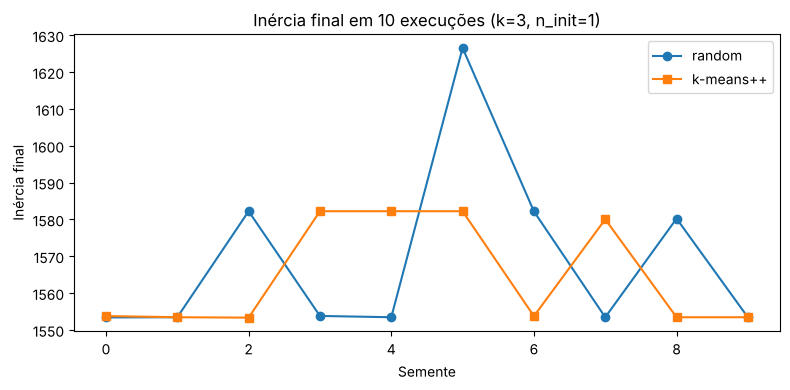

In [17]:
# comparação da dispersão dos resultados nos dois casos
resumo = pd.DataFrame({
    "mínimo": [J_random.min(), J_pp.min()],
    "máximo": [J_random.max(), J_pp.max()],
    "média": [J_random.mean(), J_pp.mean()],
    "desvio padrão": [J_random.std(ddof=1), J_pp.std(ddof=1)],
    "amplitude": [np.ptp(J_random), np.ptp(J_pp)],
}, index=["random", "k-means++"])
print(resumo.round(2).to_string())

plt.figure(figsize=(8, 4))
plt.plot(list(sementes), J_random, "o-", label="random")
plt.plot(list(sementes), J_pp, "s-", label="k-means++")
plt.xlabel("Semente"); plt.ylabel("Inércia final")
plt.title(f"Inércia final em 10 execuções (k={K}, n_init=1)")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# verificação extra: 100 execuções (k = 3 e k = 8), para ver se a vantagem do k-means++ se mantém com mais sementes
for k_ in (K, 8):
    melhor = KMeans(n_clusters=k_, n_init=50, random_state=SEED).fit(Z).inertia_   # melhor ótimo encontrado com 50 inicializações
    for init in ("random", "k-means++"):
        J = roda(init, k_, range(100))
        print(f"k={k_} {init:>9}: média={J.mean():8.2f} desvio={J.std(ddof=1):6.2f} pior={J.max():8.2f} | {np.mean(J <= melhor * 1.001):.0%} chegam ao melhor ótimo ({melhor:.1f})")

k=3    random: média= 1572.18 desvio= 24.36 pior= 1629.41 | 54% chegam ao melhor ótimo (1553.3)
k=3 k-means++: média= 1573.34 desvio= 23.46 pior= 1630.10 | 48% chegam ao melhor ótimo (1553.3)


k=8    random: média= 1052.64 desvio= 19.63 pior= 1122.48 | 0% chegam ao melhor ótimo (1022.2)
k=8 k-means++: média= 1053.34 desvio= 18.13 pior= 1093.56 | 1% chegam ao melhor ótimo (1022.2)


**Resposta.** Aparecem **mínimos locais diferentes** (a inércia final muda conforme a semente), e isso ocorre nos dois métodos.

**Que problema o k-means++ mitiga?** O k-Means converge para um mínimo **local**, que depende dos centróides iniciais; a inicialização aleatória pode colocar vários centróides na mesma região densa e deixar outras regiões sem centróide, e o algoritmo fica preso num resultado ruim. O **k-means++** sorteia o primeiro centróide ao acaso e cada novo centróide com probabilidade proporcional a $D(x)^2$ (o quadrado da distância ao centróide mais próximo já escolhido), o que **espalha** os centróides iniciais e reduz a chance de partir de uma configuração ruim.

**Dispersão.** Nas 10 execuções, o k-means++ teve menor desvio e menor amplitude que o `random` (tabela acima). **Cuidado com a conclusão:** com 100 execuções a diferença quase some para k = 3 (desvios parecidos); para k = 8 o k-means++ só reduz um pouco o pior caso. Ou seja, ajuda, mas não elimina o problema, e por isso convém usar também `n_init` maior (várias inicializações, guardando a melhor), como foi feito nas demais tarefas (`n_init=10`).

## Tarefa 5 - Interpretação e validação dos grupos: com o k escolhido, recupere os centróides, reverta-os para a escala original de gasto (desfazendo a padronização e a transformação logarítmica) e apresente-os em uma tabela e em um gráfico de barras agrupadas por categoria. Atribua a cada agrupamento um nome descritivo de natureza comercial, baseado nas categorias em que ele se destaca. Em seguida, realize uma validação externa: construa tabelas de contingência cruzando o agrupamento de cada cliente com Channel e com Region, e calcule o índice Rand ajustado (Adjusted Rand Index) entre a partição obtida e a variável Channel. Responda: o algoritmo, sem jamais ter visto o canal de venda, foi capaz de reconstruí-lo? Qual conjunto de categorias de produto mais separa Horeca de Retail? E a região geográfica — ela se reflete nos agrupamentos? Por fim, projete os dados em duas dimensões por PCA, colorindo os pontos por agrupamento, e discuta duas limitações do k-Means evidenciadas nesse gráfico: a tendência a formar grupos de geometria esférica e de tamanhos semelhantes e a sensibilidade a outliers.

Para voltar à escala de gasto, as etapas são desfeitas **na ordem inversa**: primeiro o Z-score (`inverse_transform`) e depois o log (`np.expm1`, que calcula $e^{x'} - 1$).

In [19]:
# centróides no espaço padronizado -> desfaz o Z-score -> desfaz o log
cent_log = scaler.inverse_transform(km.cluster_centers_)
cent = pd.DataFrame(np.expm1(cent_log), columns=gastos)

# dando nomes aos grupos pelo perfil dos centróides
i_varejo = int(cent["Fresh"].idxmin())       # grupo com menor gasto em frescos
i_food = int(cent["Grocery"].idxmin())       # grupo com menor gasto em mercearia
i_misto = [i for i in range(K) if i not in (i_varejo, i_food)][0]   # o restante

ordem = [i_varejo, i_food, i_misto]
nomes = ["Varejo de mercearia e limpeza", "Food service (frescos e congelados)", "Grandes compradores diversificados"]

# renumera os rótulos de cada cliente para seguir a ordem dos nomes (0, 1, 2)
mapa = {antigo: novo for novo, antigo in enumerate(ordem)}
labels = np.array([mapa[l] for l in rotulo_bruto])

cent = cent.loc[ordem].reset_index(drop=True)
cent.index = nomes
cent["n clientes"] = pd.Series(labels).value_counts().sort_index().values

print("Centróides na escala original (tabela):")
print(cent.round(0).astype({"n clientes": int}).to_string())

Centróides na escala original (tabela):
                                       Fresh    Milk  Grocery  Frozen  Detergents_Paper  Delicassen  n clientes
Varejo de mercearia e limpeza         1095.0  5635.0   9851.0   344.0            3392.0       318.0          80
Food service (frescos e congelados)   7869.0  1529.0   1985.0  1976.0             246.0       602.0         213
Grandes compradores diversificados   11287.0  7972.0  10520.0  2168.0            2762.0      1906.0         147


In [20]:
# o centróide revertido do log é uma média GEOMÉTRICA; aqui a média ARITMÉTICA real de cada grupo, para comparação
media_real = X.assign(g=labels).groupby("g").mean()
media_real.index = nomes
print("Média aritmética real dos gastos em cada grupo:")
print(media_real.round(0).to_string())

# perfil relativo: centróide / mediana geral (> 1 = acima do cliente típico; < 1 = abaixo)
print()
print("Centróide dividido pela mediana geral de cada categoria:")
print((cent[gastos] / X.median()).round(2).to_string())

Média aritmética real dos gastos em cada grupo:
                                       Fresh     Milk  Grocery  Frozen  Detergents_Paper  Delicassen
Varejo de mercearia e limpeza         2899.0   7136.0  12570.0   607.0            5554.0       783.0
Food service (frescos e congelados)  11939.0   2006.0   2502.0  3266.0             424.0       891.0
Grandes compradores diversificados   17043.0  10560.0  13334.0  4133.0            4987.0      2847.0

Centróide dividido pela mediana geral de cada categoria:
                                     Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
Varejo de mercearia e limpeza         0.13  1.55     2.07    0.23              4.15        0.33
Food service (frescos e congelados)   0.93  0.42     0.42    1.30              0.30        0.62
Grandes compradores diversificados    1.33  2.20     2.21    1.42              3.38        1.97


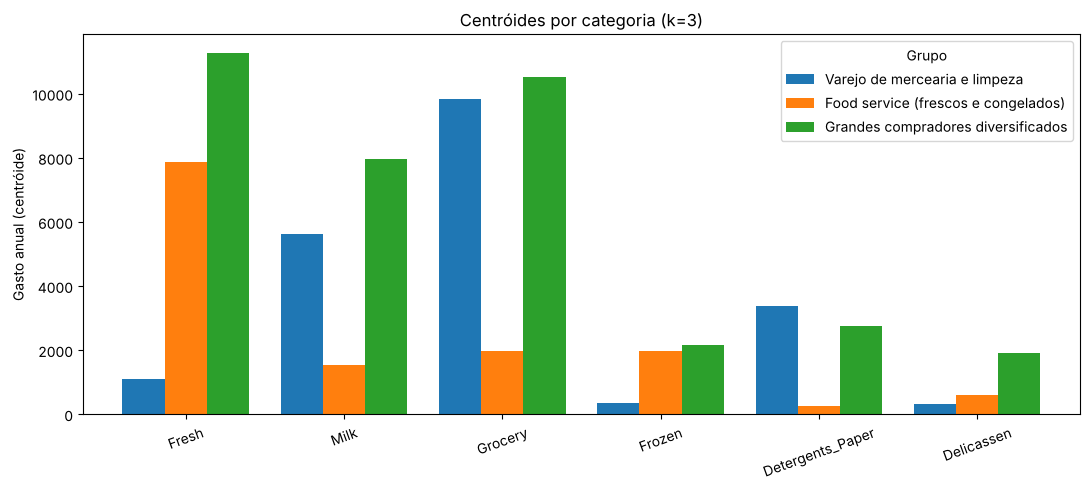

In [21]:
# gráfico de barras agrupadas por categoria (uma cor por grupo)
ax = cent[gastos].T.plot(kind="bar", figsize=(11, 5), width=0.8, rot=20)
ax.set_ylabel("Gasto anual (centróide)"); ax.set_title(f"Centróides por categoria (k={K})")
ax.legend(title="Grupo")
plt.tight_layout()
plt.show()

**Nomes dos grupos** (baseados nas categorias em que cada um se destaca):
- **Varejo de mercearia e limpeza:** gasto muito baixo em Fresh e Frozen e alto em Milk, Grocery e Detergents_Paper.
- **Food service (frescos e congelados):** é o maior grupo; gasto baixo em Milk, Grocery e Detergents_Paper (bem abaixo da mediana) e gasto em Fresh e Frozen próximo ou acima do típico (perfil de restaurantes, hotéis e cafés).
- **Grandes compradores diversificados:** acima da mediana em todas as categorias, inclusive Delicassen: contas grandes, que merecem atendimento e limite de crédito diferenciados.

### Validação externa: Channel e Region

Índice Rand ajustado (ARI): compara duas partições sem depender dos números dos grupos. **1** = partições idênticas; **≈ 0** = tão parecidas quanto o acaso.

In [22]:
canal = externos["Channel_nome"].values
regiao = externos["Region_nome"].values
grupo_nome = np.array(nomes)[labels]

# tabelas de contingência: grupo x Channel e grupo x Region
ct_canal = pd.crosstab(pd.Series(grupo_nome, name="Grupo"), pd.Series(canal, name="Channel")).loc[nomes]
ct_reg = pd.crosstab(pd.Series(grupo_nome, name="Grupo"), pd.Series(regiao, name="Region")).loc[nomes]

print("Grupo x Channel:"); print(ct_canal.to_string())
print()
print("Proporção de Horeca em cada grupo:"); print((ct_canal["Horeca"] / ct_canal.sum(axis=1)).round(3).to_string())
print()
print("Grupo x Region:"); print(ct_reg.to_string())
print()
print("Distribuição por região dentro de cada grupo (%):"); print((100 * ct_reg.div(ct_reg.sum(axis=1), axis=0)).round(1).to_string())
print("Distribuição geral (%):", (100 * pd.Series(regiao).value_counts(normalize=True)).round(1).to_dict())

Grupo x Channel:
Channel                              Horeca  Retail
Grupo                                              
Varejo de mercearia e limpeza            32      48
Food service (frescos e congelados)     210       3
Grandes compradores diversificados       56      91

Proporção de Horeca em cada grupo:
Grupo
Varejo de mercearia e limpeza          0.400
Food service (frescos e congelados)    0.986
Grandes compradores diversificados     0.381

Grupo x Region:
Region                               Lisboa  Outras  Porto
Grupo                                                     
Varejo de mercearia e limpeza            14      56     10
Food service (frescos e congelados)      40     147     26
Grandes compradores diversificados       23     113     11

Distribuição por região dentro de cada grupo (%):
Region                               Lisboa  Outras  Porto
Grupo                                                     
Varejo de mercearia e limpeza          17.5    70.0   12.5
Food s

In [23]:
# índice Rand ajustado e teste qui-quadrado (p pequeno = grupo e variável externa NÃO são independentes)
ari_canal = adjusted_rand_score(externos["Channel"], labels)
ari_regiao = adjusted_rand_score(externos["Region"], labels)
p_canal = chi2_contingency(ct_canal)[1]
p_regiao = chi2_contingency(ct_reg)[1]

print(f"ARI (grupos x Channel) = {ari_canal:.4f} | qui-quadrado p = {p_canal:.2e}")
print(f"ARI (grupos x Region)  = {ari_regiao:.4f} | qui-quadrado p = {p_regiao:.3f}")

# referência: k = 2 (mesmo número de classes do Channel)
km2 = KMeans(2, n_init=10, random_state=SEED).fit(Z)
canal01 = externos["Channel"].values - 1
conc = max((km2.labels_ == canal01).mean(), (km2.labels_ != canal01).mean())
print(f"Referência k=2: ARI(Channel) = {adjusted_rand_score(externos['Channel'], km2.labels_):.4f} | concordância = {conc:.1%}")

ARI (grupos x Channel) = 0.3504 | qui-quadrado p = 8.10e-40
ARI (grupos x Region)  = -0.0064 | qui-quadrado p = 0.493
Referência k=2: ARI(Channel) = 0.5135 | concordância = 85.9%


Detergents_Paper    2.43
Grocery             2.02
Milk                1.59
Delicassen          0.28
Fresh              -0.36
Frozen             -0.54


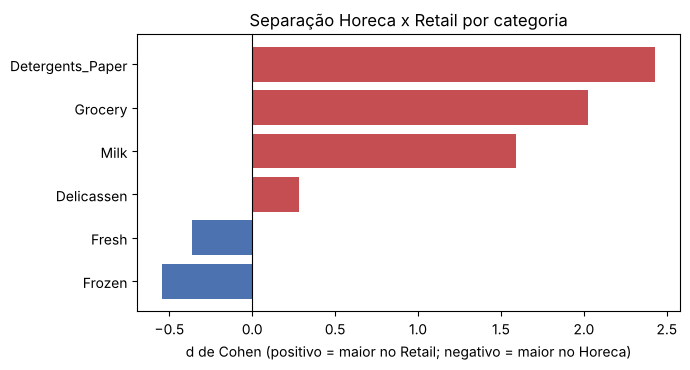

In [24]:
# quais categorias mais separam Horeca de Retail? d de Cohen (diferença entre médias / desvio padrão combinado), em log
d_log = X_log.assign(Channel=canal)
g = d_log.groupby("Channel")[gastos]
d = (g.mean().loc["Retail"] - g.mean().loc["Horeca"]) / np.sqrt((g.var().loc["Retail"] + g.var().loc["Horeca"]) / 2)
sep = d.sort_values(ascending=False)
print(sep.round(2).to_string())

plt.figure(figsize=(7, 3.8))
plt.barh(sep.index[::-1], sep.values[::-1], color=["#C44E52" if v > 0 else "#4C72B0" for v in sep.values[::-1]])
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("d de Cohen (positivo = maior no Retail; negativo = maior no Horeca)")
plt.title("Separação Horeca x Retail por categoria")
plt.tight_layout()
plt.show()

**Respostas da validação externa.**
- **O algoritmo reconstruiu o canal sem vê-lo? Em parte.** O grupo *Food service* é quase todo Horeca, e os outros dois grupos reúnem quase todos os clientes Retail (misturados com Horeca de alto gasto). O ARI com Channel é claramente maior que 0, mas com k = 3 ele cai mecanicamente em relação a uma variável binária (com k = 2 sobe, como mostra a referência acima).
- **Categorias que mais separam Horeca de Retail** (d de Cohen no log): **Detergents_Paper, Grocery e Milk** são maiores no Retail; Frozen e Fresh são maiores no Horeca.
- **Região:** **não se reflete** nos grupos. O ARI com Region é praticamente zero e o qui-quadrado não rejeita a independência; cada grupo tem aproximadamente a proporção geral de Lisboa, Porto e Outras.

### Projeção por PCA e limitações do k-Means

In [25]:
# PCA: projeta os dados padronizados (6 dimensões) em 2 dimensões, mantendo o máximo de variância
pca = PCA(n_components=2, random_state=SEED)
P = pca.fit_transform(Z)
P_cent = pca.transform(km.cluster_centers_[ordem])    # centróides no mesmo plano
print("Variância explicada: PC1 = {:.1%} | PC2 = {:.1%} | total = {:.1%}".format(*pca.explained_variance_ratio_, pca.explained_variance_ratio_.sum()))
print()
# peso de cada categoria nos componentes (o que cada eixo representa)
print(pd.DataFrame(pca.components_.T, index=gastos, columns=["PC1", "PC2"]).round(2).to_string())

# distância de cada cliente ao seu centróide (usada para destacar os outliers)
cent_Z = km.cluster_centers_[ordem]
dist = np.linalg.norm(Z - cent_Z[labels], axis=1)
fora = dist > np.percentile(dist, 97)     # os 3% mais distantes

Variância explicada: PC1 = 44.1% | PC2 = 27.2% | total = 71.3%

                   PC1   PC2
Fresh            -0.11  0.59
Milk              0.54  0.13
Grocery           0.57 -0.01
Frozen           -0.14  0.59
Detergents_Paper  0.55 -0.07
Delicassen        0.21  0.53


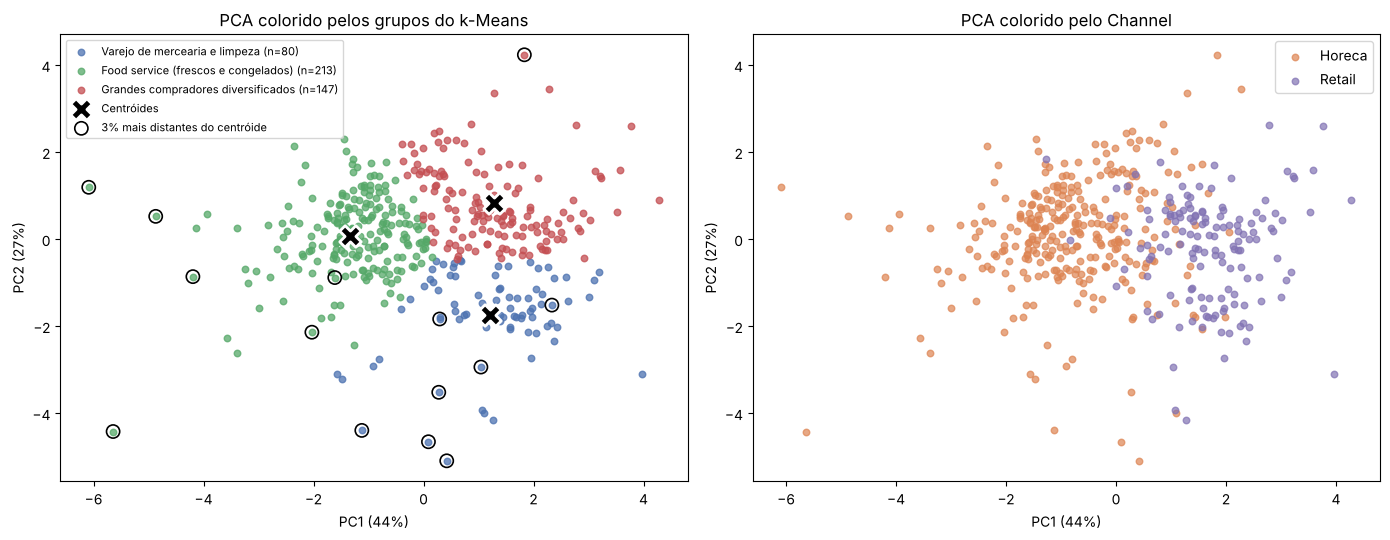

In [26]:
# gráfico PCA: à esquerda colorido pelos grupos do k-Means; à direita colorido pelo Channel real
cores = ["#4C72B0", "#55A868", "#C44E52"]
fig, eixos = plt.subplots(1, 2, figsize=(14, 5.5))
for c in range(K):
    m = labels == c
    eixos[0].scatter(P[m, 0], P[m, 1], s=22, alpha=0.75, color=cores[c], label=f"{nomes[c]} (n={m.sum()})")
eixos[0].scatter(P_cent[:, 0], P_cent[:, 1], marker="X", s=240, c="black", edgecolors="white", linewidths=2, zorder=5, label="Centróides")
eixos[0].scatter(P[fora, 0], P[fora, 1], s=90, facecolors="none", edgecolors="k", linewidths=1.2, label="3% mais distantes do centróide")
eixos[0].set_title("PCA colorido pelos grupos do k-Means"); eixos[0].legend(fontsize=8)

eixos[1].scatter(P[canal == "Horeca", 0], P[canal == "Horeca", 1], s=22, alpha=0.7, color="#DD8452", label="Horeca")
eixos[1].scatter(P[canal == "Retail", 0], P[canal == "Retail", 1], s=22, alpha=0.7, color="#8172B3", label="Retail")
eixos[1].set_title("PCA colorido pelo Channel"); eixos[1].legend()
for e in eixos:
    e.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); e.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.tight_layout()
plt.show()

In [27]:
from scipy.spatial.distance import cdist

# evidências numéricas das duas limitações
print("Tamanho dos grupos:", dict(zip(nomes, np.bincount(labels).tolist())))
print("Raio médio por grupo (distância média ao centróide):", dict(zip(nomes, [round(float(dist[labels == c].mean()), 2) for c in range(K)])))

# sensibilidade a outliers: remove os 10 clientes mais distantes dos centróides e refaz o k-Means
mantidos = np.setdiff1d(np.arange(len(Z)), np.argsort(dist)[-10:])
km_sem = KMeans(K, n_init=10, random_state=SEED).fit(Z[mantidos])
d_cent = cdist(cent_Z, km_sem.cluster_centers_)
print("Deslocamento dos centróides ao remover 10 clientes (em desvios padrão):", np.round(d_cent.min(axis=1), 3))
print(f"ARI entre a partição original e a refeita: {adjusted_rand_score(labels[mantidos], km_sem.predict(Z[mantidos])):.3f}")

print()
print("5 clientes mais distantes do centróide (escala original):")
pior = np.argsort(dist)[-5:]
print(X.iloc[pior].assign(grupo=np.array(nomes)[labels[pior]]).to_string())

Tamanho dos grupos: {'Varejo de mercearia e limpeza': 80, 'Food service (frescos e congelados)': 213, 'Grandes compradores diversificados': 147}
Raio médio por grupo (distância média ao centróide): {'Varejo de mercearia e limpeza': 2.07, 'Food service (frescos e congelados)': 1.65, 'Grandes compradores diversificados': 1.57}
Deslocamento dos centróides ao remover 10 clientes (em desvios padrão): [0.483 0.074 0.158]
ARI entre a partição original e a refeita: 0.889

5 clientes mais distantes do centróide (escala original):
     Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen                                grupo
95       3  2920     6252     440               223         709        Varejo de mercearia e limpeza
142  37036  7152     8253    2995                20           3  Food service (frescos e congelados)
338      3   333     7021   15601                15         550  Food service (frescos e congelados)
75   20398  1137        3    4407                 3         975  Food

**PCA.** Os dois primeiros componentes explicam ≈ 71% da variância (valores impressos acima): PC1 reúne Milk, Grocery e Detergents_Paper (eixo do perfil de varejo) e PC2 reúne Fresh, Frozen e Delicassen.

**Duas limitações do k-Means evidenciadas no gráfico:**
1. **Geometria esférica e tamanhos semelhantes.** O k-Means cria regiões separadas por fronteiras retas e favorece grupos compactos de variância parecida. Os pontos formam uma **nuvem contínua**, sem lacunas, e as fronteiras simplesmente cortam essa nuvem (silhueta baixa; no grupo de varejo, uma parte dos pontos tem silhueta negativa). Estruturas alongadas ou curvas seriam cortadas ao meio.
2. **Sensibilidade a outliers.** Mesmo após o log restam clientes isolados (os mais distantes do centróide, listados acima). Como o centróide é uma média e o erro é quadrático, eles pesam demais: retirando só 10 clientes (2,3% da base), os centróides se deslocam e a partição refeita deixa de ser idêntica à original (ARI < 1). Alternativas: k-medoids, tratar os outliers antes, ou DBSCAN.